# Do que os clientes reclamam, e dá para confiar numa leitura automática das avaliações?

Quem cuida de marketing e de produto recebe milhares de avaliações em texto livre e quer duas coisas delas: um
**alerta confiável de insatisfação** e uma **lista dos motivos de reclamação**, com o tamanho de cada um.

Este notebook conta a história com as tabelas. Tudo o que aparece aqui sai do pacote `nlp_avaliacoes`
(`src/`), e os mesmos números estão em `reports/resultados.json`. Base: B2W-Reviews01, avaliações de produtos
de um e-commerce brasileiro, de janeiro a maio de 2018 (licença CC BY-NC-SA 4.0). Nenhum texto de avaliação é
mostrado: só agregados.

In [1]:
%matplotlib inline
import warnings

import pandas as pd
from IPython.display import display

from nlp_avaliacoes import dados, graficos, pipeline, resumo_site

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:.3f}")
pd.set_option("display.max_colwidth", 110)

tabela, contagem = dados.carregar()
r = pipeline.executar(tabela, contagem, falar=False)  # a análise inteira: cerca de 3 minutos
print(f"{len(tabela)} avaliações usadas; MiniLM disponível: {r.densa_disponivel}")

126152 avaliações usadas; MiniLM disponível: True


## 1. A base, a limpeza e a separação no tempo

Saem as avaliações sem resposta em "recomendaria", as de texto vazio, as repetidas e os textos copiados
(o mesmo texto em avaliações diferentes: fica a primeira no tempo, para o mesmo texto não cair no treino e no
teste). O modelo aprende de janeiro a março, é ajustado em abril e é testado em maio.

In [2]:
display(pd.Series({k: v for k, v in r.base.items() if not isinstance(v, dict)}, name="valor").to_frame())
display(pd.DataFrame(r.base["periodos"]).T)

,valor
linhas_no_arquivo,132373
sem_resposta_em_recomendaria,18
texto_vazio,3383
mesma_avaliacao_repetida,1180
mesmo_texto_em_outra_avaliacao,1640
avaliacoes_usadas,126152
primeira_data,2018-01-01
ultima_data,2018-05-31
categorias,54
mediana_de_palavras,16.000


,avaliacoes,de,ate,nao_recomendaria,nota_ate_2
treino,73183,2018-01-01,2018-03-31,0.254,0.251
validação,28660,2018-04-01,2018-04-30,0.258,0.257
teste,24309,2018-05-01,2018-05-31,0.283,0.281


## 2. Dois rótulos que nem sempre concordam

Cada avaliação traz uma nota de 1 a 5 e a resposta a "recomendaria este produto?". Reclamação pode ser "nota
até 2" ou "não recomendaria". A tabela mostra, por nota, que parcela não recomendaria.

In [3]:
display(r.discordancia_por_nota)
display(pd.DataFrame(r.discordancia).T)

,avaliações,não recomendaria,IC 95% inferior,IC 95% superior
nota,,,,
1,24579,0.971,0.969,0.973
2,7983,0.753,0.744,0.762
3,15773,0.113,0.109,0.118
4,31612,0.015,0.014,0.016
5,46205,0.014,0.013,0.016


,avaliacoes,de,parcela,inferior,superior
rotulos_discordam,5611.000,126152.000,0.044,0.043,0.046
nota_baixa_mas_recomendaria,2680.000,32562.000,0.082,0.079,0.085
nota_alta_mas_nao_recomendaria,1143.000,77817.000,0.015,0.014,0.016
nota_3_e_nao_recomendaria,1788.000,15773.000,0.113,0.109,0.118
nao_recomendaria_com_nota_3_ou_mais,2931.000,32813.000,0.089,0.086,0.092


## 3. O alerta: léxico, TF-IDF de palavras e TF-IDF de caracteres

Rótulo: "não recomendaria". A linha de base é uma lista de palavras negativas escrita à mão, sem treino.
Métricas no teste (maio), com intervalo de 95% por bootstrap; as diferenças são pareadas (mesmas avaliações
sorteadas para os dois métodos).

In [4]:
display(r.desempenho.T)
display(r.diferencas.T)
for nome, grade in r.regularizacao.items():
    print(nome)
    display(grade)

,Léxico de palavras negativas,TF-IDF de palavras + regressão logística,TF-IDF de caracteres + regressão logística
AUC,0.857,0.963,0.961
AUC inf,0.852,0.960,0.959
AUC sup,0.863,0.965,0.964
precisão lendo 10%,0.890,0.958,0.951
precisão lendo 10% inf,0.878,0.950,0.943
precisão lendo 10% sup,0.902,0.967,0.960
revocação lendo 10%,0.315,0.339,0.337
revocação lendo 10% inf,0.308,0.332,0.329
revocação lendo 10% sup,0.321,0.346,0.344
leitura para pegar 80%,0.328,0.251,0.252


,TF-IDF de palavras + regressão logística − Léxico de palavras negativas,TF-IDF de palavras + regressão logística − TF-IDF de caracteres + regressão logística
AUC,0.105,0.001
AUC inf,0.101,0.001
AUC sup,0.110,0.002
AUC empata,False,False
precisão lendo 10%,0.068,0.007
precisão lendo 10% inf,0.058,0.002
precisão lendo 10% sup,0.080,0.013
precisão lendo 10% empata,False,False
revocação lendo 10%,0.024,0.002
revocação lendo 10% inf,0.020,0.001


TF-IDF de palavras + regressão logística


,AUC na validação,escolhido
C,,
0.300,0.963,False
1.000,0.965,True
3.000,0.965,False
10.000,0.963,False


TF-IDF de caracteres + regressão logística


,AUC na validação,escolhido
C,,
0.300,0.963,False
1.000,0.964,True
3.000,0.964,False
10.000,0.962,False


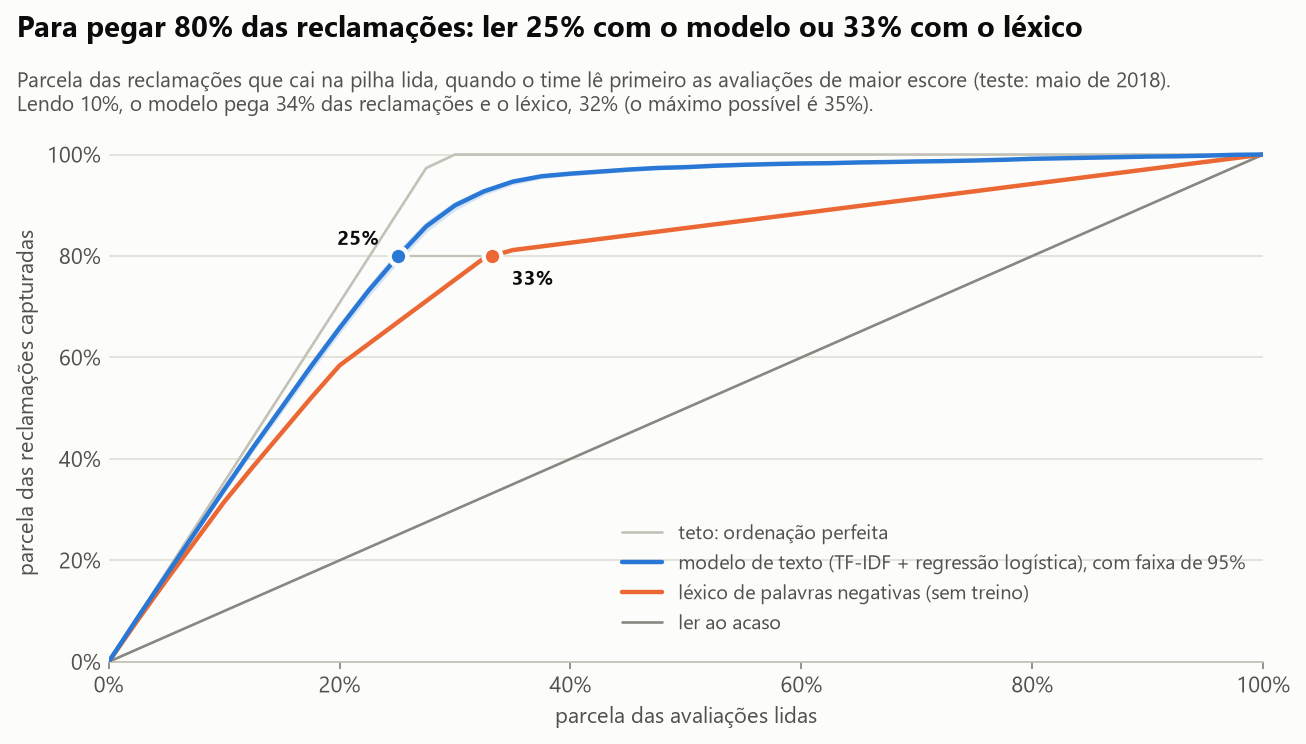

In [5]:
_ = graficos.curva_de_captura(r.curvas, pipeline.PALAVRAS, pipeline.LEXICO, 0.10)

## 4. E a nota, que já vem pronta?

A regra "nota até 2" não lê texto nenhum. Contra o rótulo "não recomendaria", ela é comparada com o modelo de
texto marcando o mesmo número de avaliações. Depois, um modelo pequeno de segundo estágio mede quanto o texto
acrescenta a quem já tem a nota, e a última tabela mostra onde o texto ajuda: dentro de cada nota.

In [6]:
display(r.regra_da_nota.T)
display(r.nota_e_texto.T)
display(r.nota_e_texto_diferenca.T)
display(r.texto_dentro_da_nota)

,"Regra ""nota até 2""","Texto, marcando o mesmo volume"
parcela marcada,0.281,0.281
precisão,0.913,0.874
precisão inf,0.906,0.863
precisão sup,0.920,0.884
revocação,0.910,0.870
revocação inf,0.903,0.859
revocação sup,0.916,0.880


,Só a nota,Nota + texto
AUC,0.964,0.974
AUC inf,0.961,0.971
AUC sup,0.967,0.976
precisão lendo 10%,0.968,0.984
precisão lendo 10% inf,0.963,0.979
precisão lendo 10% sup,0.972,0.988
revocação lendo 10%,0.343,0.348
revocação lendo 10% inf,0.336,0.341
revocação lendo 10% sup,0.349,0.355
leitura para pegar 80%,0.240,0.236


,Nota + texto − Só a nota
AUC,0.010
AUC inf,0.008
AUC sup,0.011
AUC empata,False
precisão lendo 10%,0.016
precisão lendo 10% inf,0.011
precisão lendo 10% sup,0.021
precisão lendo 10% empata,False
revocação lendo 10%,0.006
revocação lendo 10% inf,0.004


,avaliações,não recomendaria,AUC do texto,IC 95% inferior,IC 95% superior
nota,,,,,
1,5165,0.968,0.665,0.625,0.706
2,1675,0.746,0.709,0.681,0.740
3,3090,0.118,0.808,0.786,0.830
4,5887,0.017,0.684,0.617,0.745
5,8492,0.018,0.599,0.552,0.653


## 5. Ruído de rótulo: a métrica depende do gabarito

O mesmo escore, avaliado contra cada definição de reclamação. Treinar com um rótulo ou com o outro quase não
muda o modelo; trocar o gabarito muda a AUC.

avaliações  reclamações   AUC  \
treinado com       avaliado contra                                              
"não recomendaria" não recomendaria                  24309        0.283 0.963   
                   nota até 2                        24309        0.281 0.980   
                   só onde os dois concordam         23095        0.270 0.989   
                   qualquer um dos dois sinais       24309        0.307 0.968   
"nota até 2"       não recomendaria                  24309        0.283 0.962   
                   nota até 2                        24309        0.281 0.981   
                   só onde os dois concordam         23095        0.270 0.989   
                   qualquer um dos dois sinais       24309        0.307 0.968   

                                                IC 95% inferior  \
treinado com       avaliado contra                                
"não recomendaria" não recomendaria                       0.960   
                   nota até 2                             0.978   
                   só onde os dois concordam              0.988   
                   qualquer um dos dois sinais            0.965   
"nota até 2"       não recomendaria                       0.959   
                   nota até 2                             0.979   
                   só onde os dois concordam              0.988   
                   qualquer um dos dois sinais            0.965   

                                                IC 95% superior  
treinado com       avaliado contra                               
"não recomendaria" não recomendaria                       0.965  
                   nota até 2                             0.982  
                   só onde os dois concordam              0.990  
                   qualquer um dos dois sinais            0.970  
"nota até 2"       não recomendaria                       0.964  
                   nota até 2                             0.982  
                   só onde os dois concordam              0.990  
                   qualquer um dos dois sinais            0.970

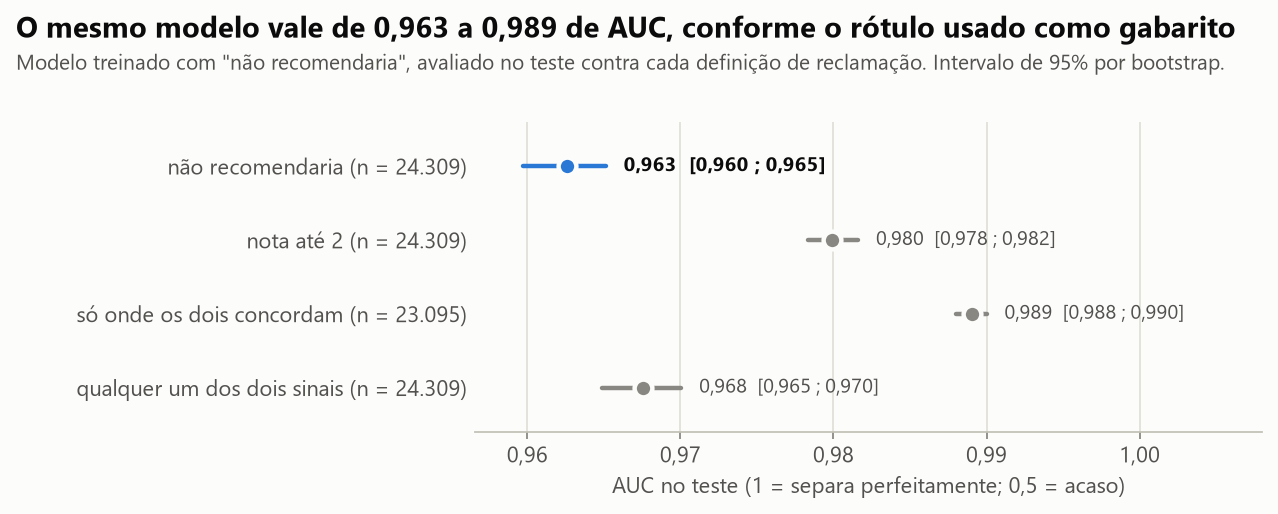

In [7]:
display(r.auc_por_rotulo)
_ = graficos.auc_por_rotulo(r.auc_por_rotulo, '"não recomendaria"')

Entre as avaliações de nota 4 ou 5 que recomendariam, quantas o modelo lê como reclamação? E o que há
nelas? A segunda tabela resume a leitura manual dos 45 "alarmes falsos" de maior escore e das 45 "reclamações
perdidas" de menor escore (`data/leitura_manual_de_erros.csv`, sem texto).

In [8]:
display(pd.Series(r.nota_alta_texto_negativo, name="nota 4 ou 5, recomendaria").to_frame())
display(r.leitura)

,"nota 4 ou 5, recomendaria"
avaliacoes,14123.000
lidas_como_reclamacao,187.000
parcela,0.013
inferior,0.011
superior,0.015


avaliações  \
tipo               categoria                                                   
alarme falso       reclamação de entrega ou atendimento                   32   
                   reclamação do produto recebido                          9   
                   ironia ou comentário sobre o preço do anúncio           3   
                   ambíguo                                                 1   
reclamação perdida elogio e crítica no mesmo texto                        26   
                   crítica sem palavra típica de reclamação                9   
                   pergunta ou texto sem relato da compra                  6   
                   ironia ou piada                                         4   

                                                                  de  parcela  \
tipo               categoria                                                    
alarme falso       reclamação de entrega ou atendimento           45    0.711   
                   reclamação do produto recebido                 45    0.200   
                   ironia ou comentário sobre o preço do anúncio  45    0.067   
                   ambíguo                                        45    0.022   
reclamação perdida elogio e crítica no mesmo texto                45    0.578   
                   crítica sem palavra típica de reclamação       45    0.200   
                   pergunta ou texto sem relato da compra         45    0.133   
                   ironia ou piada                                45    0.089   

                                                                  IC 95% inferior  \
tipo               categoria                                                        
alarme falso       reclamação de entrega ou atendimento                     0.566   
                   reclamação do produto recebido                           0.109   
                   ironia ou comentário sobre o preço do anúncio            0.023   
                   ambíguo                                                  0.004   
reclamação perdida elogio e crítica no mesmo texto                          0.433   
                   crítica sem palavra típica de reclamação                 0.109   
                   pergunta ou texto sem relato da compra                   0.063   
                   ironia ou piada                                          0.035   

                                                                  IC 95% superior  
tipo               categoria                                                       
alarme falso       reclamação de entrega ou atendimento                     0.823  
                   reclamação do produto recebido                           0.338  
                   ironia ou comentário sobre o preço do anúncio            0.179  
                   ambíguo                                                  0.116  
reclamação perdida elogio e crítica no mesmo texto                          0.710  
                   crítica sem palavra típica de reclamação                 0.338  
                   pergunta ou texto sem relato da compra                   0.262  
                   ironia ou piada                                          0.207

## 6. Calibração e onde o alerta erra

,erro_de_calibracao,inferior,superior,brier,probabilidade_media,frequencia_observada,valor
bruta,0.033,0.030,0.036,0.059,0.283,0.283,NaN
recalibrada,0.021,0.018,0.024,0.058,0.280,0.283,NaN
diferenca_recalibrada_menos_bruta,NaN,-0.014,-0.011,NaN,NaN,NaN,-0.012


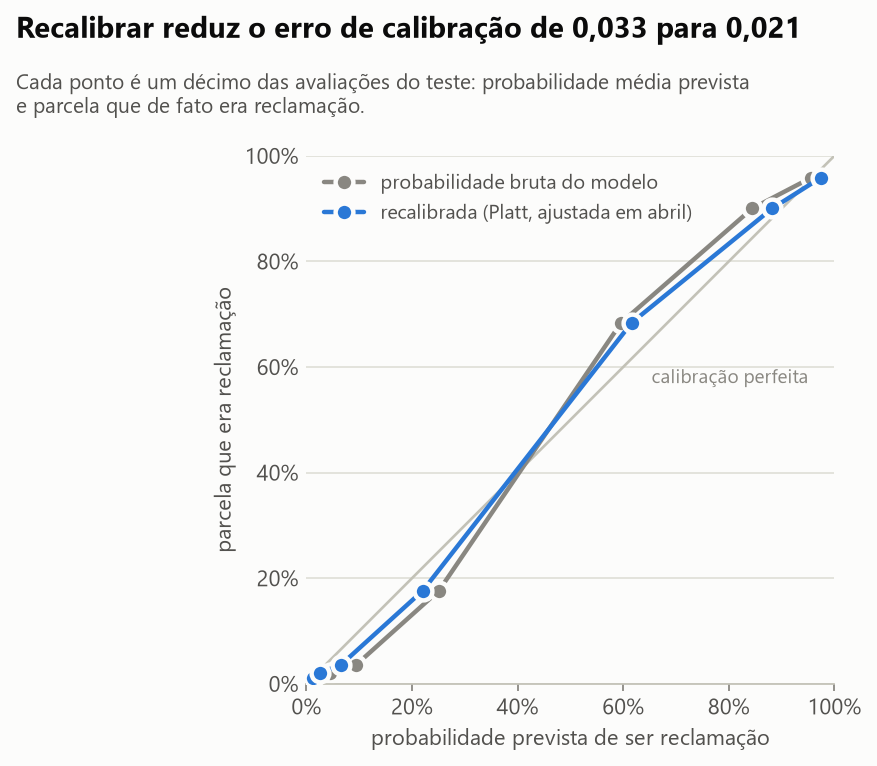

In [9]:
display(pd.DataFrame({k: v for k, v in r.calibracao.items() if isinstance(v, dict)}).T)
_ = graficos.calibracao(r.curvas_de_calibracao, r.calibracao)

In [10]:
display(r.erros)

avaliações  reclamações   AUC  \
recorte          grupo                                                     
assunto          fala de entrega ou prazo        9060        0.320 0.962   
                 não fala de entrega            15249        0.260 0.961   
gênero           F                              11054        0.280 0.965   
                 M                              12348        0.286 0.960   
                 não informado                    907        0.266 0.955   
idade            18 a 29                         4497        0.286 0.962   
                 30 a 39                         7503        0.300 0.961   
                 40 a 49                         5344        0.296 0.965   
                 50 a 59                         3542        0.257 0.965   
                 60 ou mais                      2138        0.231 0.967   
                 não informada                   1285        0.272 0.959   
região           Centro-Oeste                    1233        0.294 0.957   
                 Nordeste                        3300        0.332 0.959   
                 Norte                            552        0.277 0.947   
                 Sudeste                        15229        0.274 0.964   
                 Sul                             3115        0.274 0.967   
                 não informada                    880        0.265 0.954   
tamanho do texto 11 a 20                        10271        0.228 0.963   
                 21 a 40                         5792        0.397 0.952   
                 6 a 10                          5057        0.125 0.952   
                 até 5 palavras                   144        0.076 0.968   
                 mais de 40                      3045        0.522 0.929   

                                           IC 95% inferior  IC 95% superior  \
recorte          grupo                                                        
assunto          fala de entrega ou prazo            0.958            0.967   
                 não fala de entrega                 0.958            0.965   
gênero           F                                   0.961            0.969   
                 M                                   0.956            0.964   
                 não informado                       0.938            0.967   
idade            18 a 29                             0.955            0.968   
                 30 a 39                             0.956            0.965   
                 40 a 49                             0.959            0.971   
                 50 a 59                             0.956            0.971   
                 60 ou mais                          0.958            0.976   
                 não informada                       0.947            0.971   
região           Centro-Oeste                        0.942            0.971   
                 Nordeste                            0.952            0.966   
                 Norte                               0.923            0.968   
                 Sudeste                             0.960            0.968   
                 Sul                                 0.959            0.974   
                 não informada                       0.938            0.966   
tamanho do texto 11 a 20                             0.959            0.968   
                 21 a 40                             0.947            0.957   
                 6 a 10                              0.939            0.963   
                 até 5 palavras                      0.914            1.000   
                 mais de 40                          0.920            0.937   

                                           reclamações perdidas  \
recorte          grupo                                            
assunto          fala de entrega ou prazo                 0.083   
                 não fala de entrega                      0.179   
gênero           F                                   

## 7. Motivos de reclamação: os temas e a sua estabilidade

Reclamações com rótulo sem ambiguidade (nota até 2 e "não recomendaria"). O NMF sobre TF-IDF é ajustado nas
reclamações de janeiro a março; o tamanho de cada motivo é medido em maio. A estabilidade responde: se eu
repetir o ajuste com outra semente e outra subamostra, os mesmos temas voltam?

,estabilidade,mínimo,máximo,pares de execuções
temas,,,,
4,0.674,0.385,0.909,10
6,0.595,0.381,0.854,10
8,0.704,0.631,0.867,10
10,0.617,0.484,0.809,45
12,0.571,0.497,0.772,10


,modelo adotado
temas,10.000
execucoes,10.000
pares,45.000
estabilidade,0.617
minimo,0.484
maximo,0.809
palavras_repetidas_em_10,7.633
reclamacoes_no_treino,16925.000
reclamacoes_no_teste,6247.000
reclamacoes_fora_do_treino,12957.000


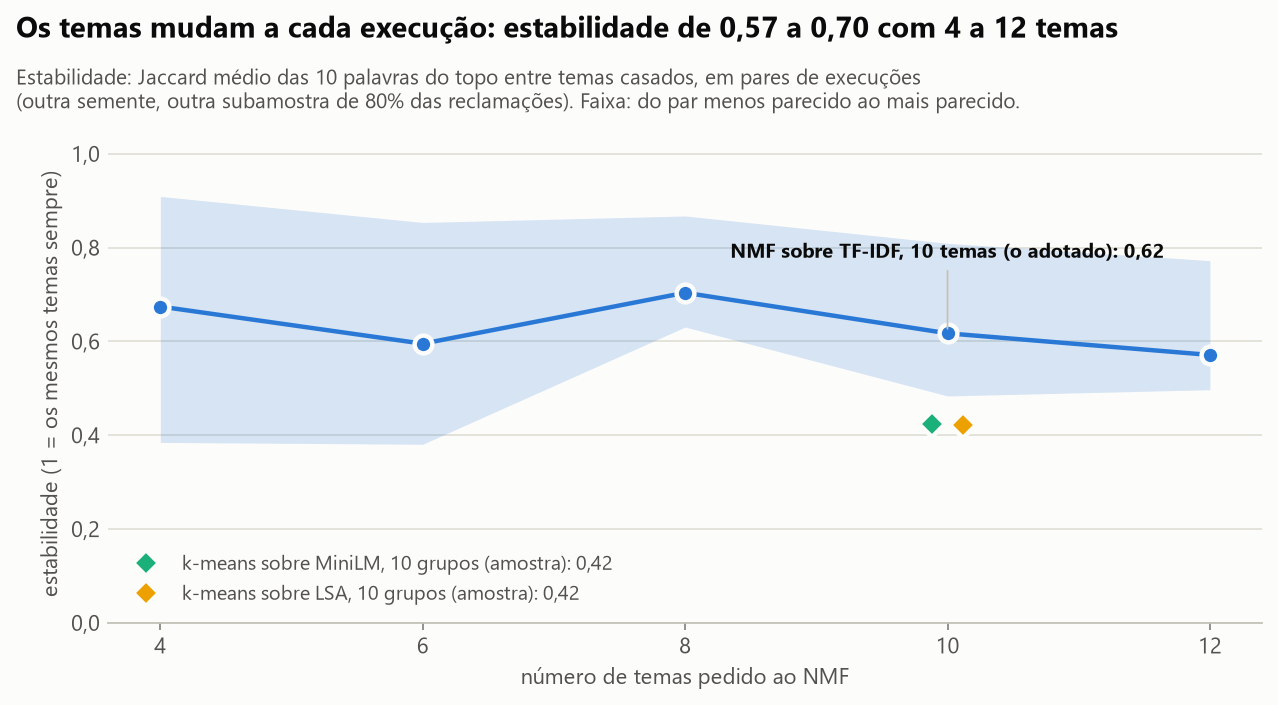

In [11]:
display(r.estabilidade)
display(pd.Series(r.estabilidade_do_modelo, name="modelo adotado").to_frame())
_ = graficos.estabilidade_dos_temas(r.estabilidade, r.numero_de_temas, resumo_site.estabilidade_dos_agrupamentos(r))

In [12]:
display(r.temas)

,motivo,palavras,estabilidade,parcela
tema,,,,
1,Produto não recebido,"nao_recebi, hoje, nao_avaliar, mes, agora, momento, comprei, paguei, gostaria, quero",0.827,0.058
2,Loja e atendimento,"americanas, compra, site, loja, nem, agora, nada, nunca, recebi, comprei",0.879,0.142
3,Material e acabamento ruins,"qualidade, pessima, ruim, material, baixa, nao_recomendo, fragil, ma, acabamento, horrivel",0.824,0.077
4,"Defeito, avaria ou item errado","defeito, veio, troca, chegou, quebrado, devolucao, faltando, errado, nao_funciona, trocar",0.650,0.112
5,Atraso e prazo de entrega,"entrega, prazo, dias, atraso, demora, dia, passou, data, nao_entregue, previsao",0.759,0.057
6,Produto não recebido,"avaliar, nao_posso, posso, nao_entregue, nem, recebi, algo, avaliacao, receber, pedido",0.706,0.046
7,Diferente do esperado ou do anunciado,"nao_gostei, ruim, nao_recomendo, foto, fraco, achei, diferente, agua, material, pequeno",0.633,0.069
8,Produto não recebido,"nao_chegou, hoje, mes, dia, comprei, chegar, agora, faz, nada, pedido",0.400,0.038
9,Desempenho ruim no uso,"mas, uso, comprei, mesmo, ruim, bem, aparelho, sem, celular, nao_funciona",0.714,0.304


Cada tema recebe o nome de um motivo por uma regra de palavras-âncora (`analise.MOTIVOS`), aplicada da mesma
forma a qualquer execução. Dois intervalos: o de amostragem (temas fixos) e o de reajuste (temas reaprendidos).

,família,parcela,amostragem inf,amostragem sup,reajuste inf,reajuste sup,menor entre execuções,maior entre execuções,temas,estabilidade,execuções em que aparece
motivo,,,,,,,,,,,
Produto não recebido,entrega e loja,0.142,0.134,0.151,0.089,0.145,0.091,0.141,3,0.644,10
Atraso e prazo de entrega,entrega e loja,0.057,0.052,0.063,0.057,0.113,0.060,0.110,1,0.759,10
"Defeito, avaria ou item errado",produto,0.112,0.105,0.120,0.088,0.181,0.091,0.179,1,0.650,10
Desempenho ruim no uso,produto,0.304,0.293,0.317,0.198,0.318,0.202,0.315,1,0.714,10
Material e acabamento ruins,produto,0.077,0.071,0.085,0.066,0.091,0.069,0.089,1,0.824,10
Diferente do esperado ou do anunciado,produto,0.069,0.063,0.076,0.000,0.197,0.000,0.194,1,0.633,8
Loja e atendimento,entrega e loja,0.142,0.133,0.150,0.119,0.236,0.121,0.233,1,0.879,10
Desabafo sem motivo claro,sem motivo claro,0.095,0.088,0.103,0.000,0.135,0.000,0.130,1,0.564,8
Outros,sem motivo claro,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0,NaN,0


,parcela,IC 95% inferior,IC 95% superior,menor entre execuções,maior entre execuções
família,,,,,
entrega e loja,0.341,0.330,0.352,0.334,0.431
produto,0.564,0.552,0.575,0.441,0.603
sem motivo claro,0.095,0.088,0.103,0.000,0.131


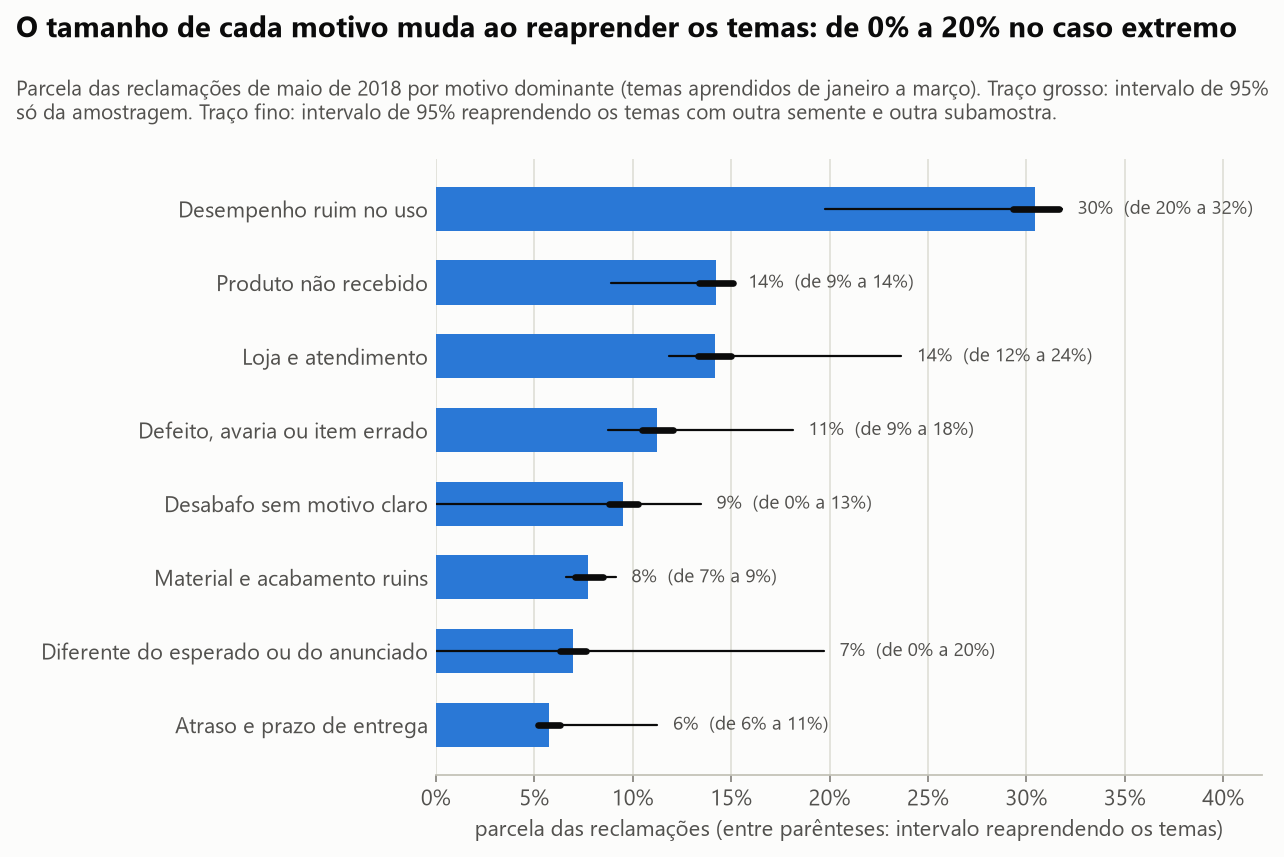

In [13]:
display(r.motivos)
display(r.familias)
_ = graficos.motivos(r.motivos)

,reclamações,Produto não recebido,Atraso e prazo de entrega,"Defeito, avaria ou item errado",Desempenho ruim no uso,Material e acabamento ruins,Diferente do esperado ou do anunciado,Loja e atendimento,Desabafo sem motivo claro,Outros
Celulares e Smartphones,1523,0.144,0.076,0.101,0.374,0.037,0.051,0.133,0.082,0.001
Móveis,1146,0.199,0.124,0.120,0.160,0.098,0.053,0.163,0.083,0.000
Informática e Acessórios,991,0.190,0.070,0.118,0.328,0.061,0.039,0.131,0.064,0.000
Beleza e Perfumaria,831,0.165,0.046,0.100,0.291,0.054,0.103,0.140,0.101,0.000
Utilidades Domésticas,758,0.136,0.045,0.119,0.284,0.112,0.104,0.102,0.099,0.000
Eletroportáteis,680,0.101,0.037,0.125,0.351,0.063,0.093,0.128,0.101,0.000
Casa e Construção,608,0.202,0.046,0.105,0.285,0.066,0.059,0.138,0.099,0.000
TV e Home Theater,565,0.113,0.050,0.110,0.398,0.080,0.074,0.110,0.065,0.000


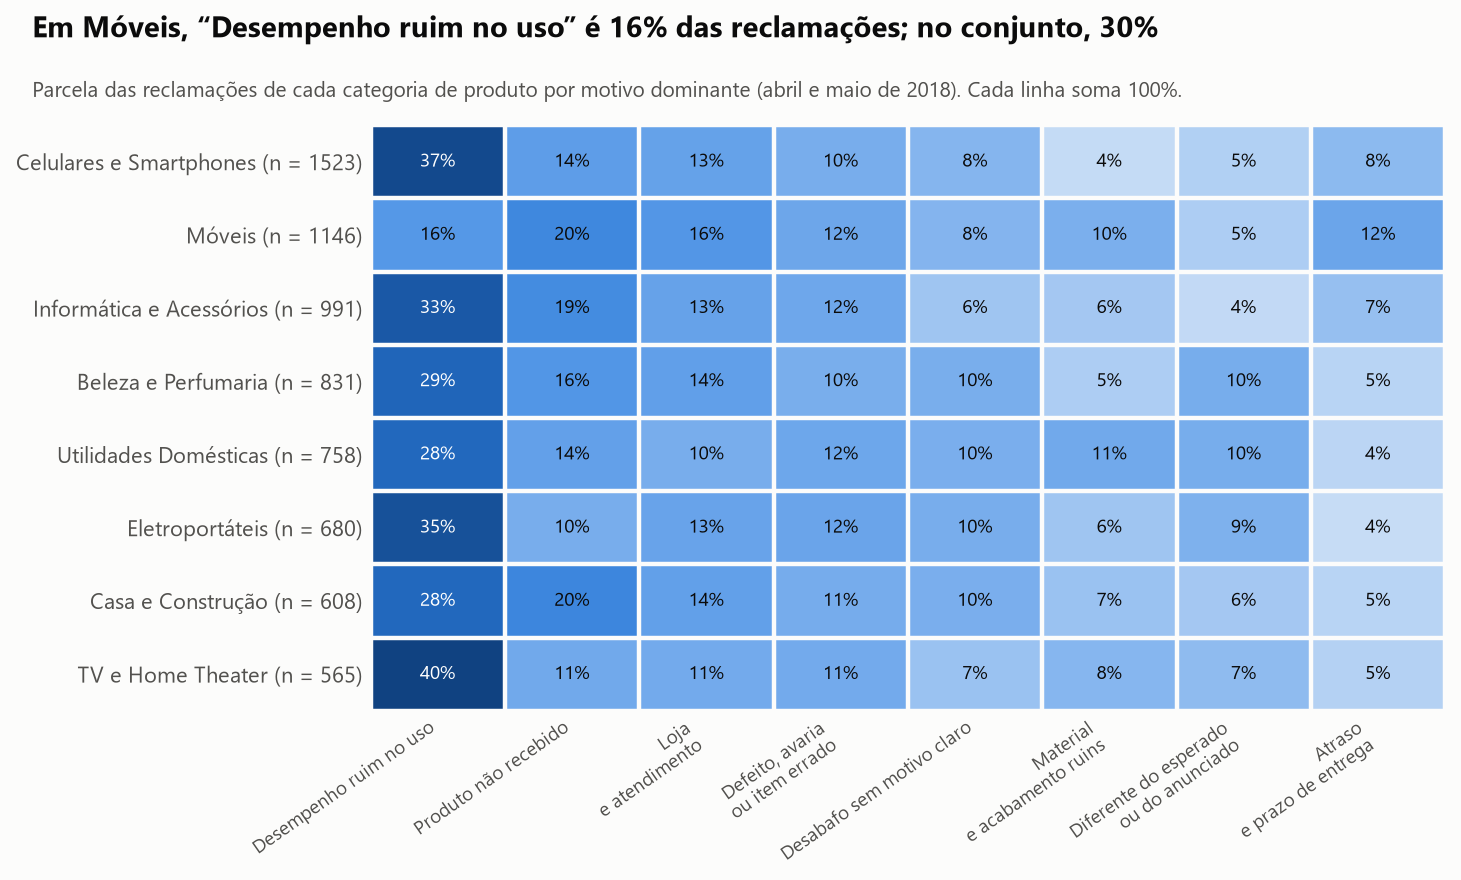

In [14]:
display(r.por_categoria)
_ = graficos.motivos_por_categoria(r.por_categoria, r.motivos["parcela"])

In [15]:
display(r.por_mes)

,reclamações,Produto não recebido,Atraso e prazo de entrega,"Defeito, avaria ou item errado",Desempenho ruim no uso,Material e acabamento ruins,Diferente do esperado ou do anunciado,Loja e atendimento,Desabafo sem motivo claro,Outros
2018-01,7070,0.164,0.053,0.113,0.301,0.082,0.067,0.138,0.080,0.000
2018-02,2937,0.088,0.054,0.110,0.372,0.082,0.075,0.127,0.092,0.000
2018-03,6918,0.172,0.063,0.112,0.282,0.078,0.065,0.144,0.084,0.001
2018-04,6710,0.181,0.068,0.110,0.267,0.078,0.070,0.142,0.085,0.000
2018-05,6247,0.142,0.057,0.112,0.304,0.077,0.069,0.142,0.095,0.000


## 8. Representação densa contra TF-IDF, na mesma amostra

O modelo de linguagem (MiniLM multilíngue, em ONNX) foi rodado uma vez numa amostra fixa de 20 mil avaliações.
Classificadores treinados nas mesmas 9 mil avaliações e testados nas mesmas 5 mil; depois, agrupamento k-means
sobre a representação densa contra o NMF, nas mesmas reclamações.

In [16]:
display(pd.Series({k: v for k, v in r.amostra.items() if not isinstance(v, dict)}, name="amostra").to_frame())
display(r.representacoes.T)
display(r.representacoes_diferencas.T)

,amostra
avaliacoes,20000
treino,9000
teste,5000
reclamacoes_para_agrupar,8107
termos_do_tfidf,15683


,TF-IDF de palavras,LSA (200 dimensões),MiniLM multilíngue (384 dimensões),"TF-IDF de palavras, treinado na base inteira"
AUC,0.954,0.952,0.946,0.959
AUC inf,0.946,0.944,0.937,0.952
AUC sup,0.961,0.958,0.952,0.966
precisão lendo 10%,0.938,0.956,0.932,0.950
precisão lendo 10% inf,0.916,0.936,0.910,0.930
precisão lendo 10% sup,0.957,0.972,0.954,0.968
revocação lendo 10%,0.332,0.338,0.330,0.336
revocação lendo 10% inf,0.317,0.323,0.316,0.321
revocação lendo 10% sup,0.346,0.353,0.344,0.351
leitura para pegar 80%,0.257,0.264,0.268,0.253


,LSA (200 dimensões) − TF-IDF de palavras,MiniLM multilíngue (384 dimensões) − TF-IDF de palavras,"TF-IDF de palavras, treinado na base inteira − TF-IDF de palavras"
AUC,-0.002,-0.008,0.006
AUC inf,-0.004,-0.013,0.004
AUC sup,0.000,-0.004,0.007
AUC empata,True,False,False
precisão lendo 10%,0.018,-0.006,0.012
precisão lendo 10% inf,0.002,-0.026,0.002
precisão lendo 10% sup,0.034,0.016,0.026
precisão lendo 10% empata,False,True,False
revocação lendo 10%,0.006,-0.002,0.004
revocação lendo 10% inf,0.001,-0.009,0.001


In [17]:
display(r.agrupamentos)
display(r.agrupamentos_parcelas)

,estabilidade,mínimo,máximo,palavras em comum com o NMF,mesmo motivo que o NMF
NMF sobre TF-IDF,0.541,0.388,0.717,1.000,1.000
k-means sobre MiniLM,0.424,0.276,0.685,0.193,0.334
k-means sobre LSA,0.422,0.360,0.474,0.369,0.515


,NMF sobre TF-IDF,k-means sobre MiniLM,k-means sobre LSA
motivo,,,
Produto não recebido,0.158,0.168,0.152
Atraso e prazo de entrega,0.060,0.139,0.000
"Defeito, avaria ou item errado",0.110,0.102,0.099
Desempenho ruim no uso,0.332,0.151,0.170
Material e acabamento ruins,0.077,0.126,0.068
Diferente do esperado ou do anunciado,0.063,0.108,0.317
Loja e atendimento,0.130,0.103,0.194
Desabafo sem motivo claro,0.070,0.103,0.000
Outros,0.001,0.000,0.000


## 9. O que fica

- **O alerta é confiável e simples.** TF-IDF de palavras com regressão logística; caracteres e representação
  densa não melhoram. O léxico feito à mão já acerta bastante na pilha pequena e perde quando é preciso ler mais.
- **Se a nota existe, ela é o melhor alerta.** O texto acrescenta pouco à nota no geral e ajuda mais na nota 3.
- **A métrica depende do rótulo.** Boa parte dos "erros" mais confiantes do modelo são erros do rótulo:
  reclamações de entrega escritas com nota alta.
- **Os motivos são um mapa, não uma medida.** Os temas mudam entre execuções e entre métodos; as famílias
  (entrega e loja, produto) são mais estáveis do que os motivos dentro delas.